# 06 · PBL 3 — Gradient Boosting for Weekly Demand Forecasting
**Unit 5 (boosting / ensemble learning).** Run `01_Create_Dataset` and `05_PBL1_Regression` first.
Reads `dataset/store_weekly.csv` and `results/05_regression/` · creates `results/06_boosting/`.

Same task, same features, same train/test weeks and same metrics as PBL 1, so the results are directly comparable.

In [1]:
# ---- Only on Google Colab (skip on your own computer) ----
# !pip install -q hmmlearn
# from google.colab import drive; drive.mount("/content/drive")
# %cd /content/drive/MyDrive/QuickCommerce_ML_Project_Final

import os, json, time, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
warnings.filterwarnings("ignore")
logging.getLogger("hmmlearn").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42
DATE = "%d-%m-%Y"

def inr(x):
    # Indian digit grouping: 113390 -> 1,13,390
    s = f"{abs(x):.0f}"; head, tail = s[:-3], s[-3:]; parts = []
    while len(head) > 2:
        parts.insert(0, head[-2:]); head = head[:-2]
    if head: parts.insert(0, head)
    return ("-" if x < 0 else "") + ",".join(parts + [tail])

# chart style — colour-blind-safe palette in fixed order
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 9.5, "font.size": 8.5, "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 1.5, "figure.dpi": 110, "legend.frameon": False,
})

OUT = "results/06_boosting"                      # every file this notebook creates goes here
os.makedirs(OUT, exist_ok=True)
def save_fig(fig, name):
    fig.savefig(f"{OUT}/{name}.png", dpi=240, bbox_inches="tight")
    plt.show()

In [2]:
weekly = pd.read_csv("dataset/store_weekly.csv", parse_dates=["week"])
FEATURES = ["lag1", "lag2", "lag4", "roll4", "store_age_w", "festival_days", "monsoon",
            "area_Premium Residential", "area_Residential", "area_Student / PG Hub"]
SPLIT = pd.Timestamp("2026-03-30")
train, test = weekly[weekly.week < SPLIT], weekly[weekly.week >= SPLIT]
y_train, y_test = train.orders, test.orders
pbl1 = pd.read_csv("results/05_regression/metrics.csv", index_col=0)
def metrics(y, p):
    return {"MAE": float(mean_absolute_error(y, p)), "RMSE": float(mean_squared_error(y, p) ** 0.5),
            "R²": float(r2_score(y, p)), "WAPE": float(np.abs(y - p).sum() / y.sum())}
print(f"Train {inr(len(train))} store-weeks | test {inr(len(test))} store-weeks")

Train 2,531 store-weeks | test 1,508 store-weeks


## 6.0 Additional feature analysis for boosting

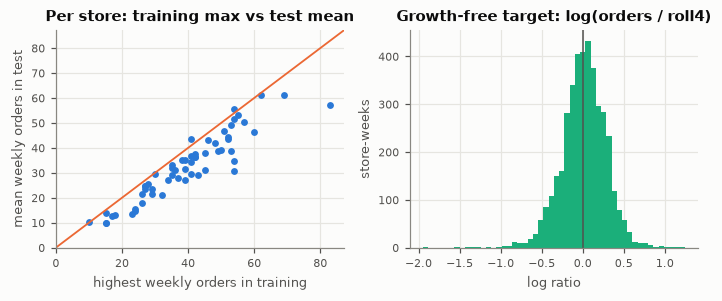

Test store-weeks above the store's training maximum: 19.2%
Growth-free target: mean +0.011, std 0.270, skew -0.40


In [3]:
tr_max = train.groupby("store_id").orders.max()
test_mean = test.groupby("store_id").orders.mean()
ratio = np.log(weekly.orders / weekly.roll4)
fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.8))
axes[0].scatter(tr_max, test_mean.reindex(tr_max.index), s=12, color=BLUE)
lim = [0, max(tr_max.max(), test_mean.max()) * 1.05]
axes[0].plot(lim, lim, color=ORANGE, lw=1.2)
axes[0].set(title="Per store: training max vs test mean", xlabel="highest weekly orders in training",
            ylabel="mean weekly orders in test", xlim=lim, ylim=lim)
axes[1].hist(ratio, bins=50, color=AQUA)
axes[1].axvline(0, color=INK2, lw=1)
axes[1].set(title="Growth-free target: log(orders / roll4)", xlabel="log ratio", ylabel="store-weeks")
plt.tight_layout(); save_fig(fig, "boosting_feature_analysis")
above = (test.orders.values > test.store_id.map(tr_max).values).mean()
print(f"Test store-weeks above the store's training maximum: {above:.1%}")
print(f"Growth-free target: mean {ratio.mean():+.3f}, std {ratio.std():.3f}, skew {ratio.skew():+.2f}")

## 6.1 Gradient boosting
Gradient boosting builds an **ensemble of small regression trees (CART)** one after another. Each new tree is fitted
to the residuals (negative gradient of the squared-error loss) of the ensemble so far, and is added with a small
learning rate ν:
$$F_m(x) = F_{m-1}(x) + \nu \, h_m(x), \qquad h_m \approx -\frac{\partial L(y, F_{m-1}(x))}{\partial F_{m-1}(x)} = y - F_{m-1}(x)$$
It captures non-linear effects and interactions automatically, which linear models cannot.

**Hyperparameters** are chosen by 5-fold **time-series cross-validation** on the training weeks only
(each fold trains on earlier weeks and validates on the following weeks).

### Step 1 — boosting on the original features

In [4]:
tscv = TimeSeriesSplit(n_splits=5)
grid = {"n_estimators": [200, 400, 800], "learning_rate": [0.02, 0.05], "max_depth": [2, 3]}
t0 = time.perf_counter()
gb_raw = GridSearchCV(GradientBoostingRegressor(subsample=0.8, random_state=SEED), grid, cv=tscv,
                      scoring="neg_mean_absolute_error").fit(train[FEATURES], y_train)
p_raw = gb_raw.predict(test[FEATURES])
print("Best parameters:", gb_raw.best_params_, f"| search time {time.perf_counter() - t0:.0f} s")
print("Test:", {k: round(v, 3) for k, v in metrics(y_test, p_raw).items()})
print(f"Test weeks above the store's highest training week: {(test.orders.values > test.store_id.map(train.groupby('store_id').orders.max()).values).mean():.0%}")

Best parameters: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200} | search time 56 s
Test: {'MAE': 5.917, 'RMSE': 8.05, 'R²': 0.71, 'WAPE': 0.181}
Test weeks above the store's highest training week: 19%


**Diagnosis.** Trees can only output values seen in training: they cannot **extrapolate**. The business keeps
growing, so many test weeks are higher than anything the store had in training, and the trees under-predict them.

### Step 2 — boosting on a growth-free target
The fix is to let the trees model the **relative change** instead of the level:
$$\text{target} = \log\frac{\text{orders}_t}{\text{roll4}_t}, \qquad \hat{y}_t = \text{roll4}_t \cdot e^{\hat{F}(x_t)}$$
with relative lag features `lag1/roll4`, `lag2/roll4`, `lag4/roll4` and the week of the year.

In [5]:
for d in (train, test):
    d["r1"], d["r2"], d["r4"] = d.lag1 / d.roll4, d.lag2 / d.roll4, d.lag4 / d.roll4
    d["woy"] = d.week.dt.isocalendar().week.astype(int)
REL = ["r1", "r2", "r4", "roll4", "store_age_w", "festival_days", "monsoon", "woy",
       "area_Premium Residential", "area_Residential", "area_Student / PG Hub"]
z_train = np.log(y_train / train.roll4)
t0 = time.perf_counter()
gb = GridSearchCV(GradientBoostingRegressor(subsample=0.8, random_state=SEED), grid, cv=tscv,
                  scoring="neg_mean_absolute_error").fit(train[REL], z_train)
GB_TIME = time.perf_counter() - t0
p_gb = test.roll4 * np.exp(gb.predict(test[REL]))
cv_tab = pd.DataFrame(gb.cv_results_)[["param_n_estimators", "param_learning_rate", "param_max_depth", "mean_test_score"]]
cv_tab["CV MAE (log ratio)"] = -cv_tab.pop("mean_test_score")
cv_tab.sort_values("CV MAE (log ratio)").round(4).to_csv(f"{OUT}/cv_results.csv", index=False)
print("Best parameters:", gb.best_params_, f"| search time {GB_TIME:.0f} s")
print("Test:", {k: round(v, 3) for k, v in metrics(y_test, p_gb).items()})
cv_tab.sort_values("CV MAE (log ratio)").head(6).round(4)

Best parameters: {'learning_rate': 0.02, 'max_depth': 2, 'n_estimators': 200} | search time 50 s
Test: {'MAE': 5.315, 'RMSE': 6.939, 'R²': 0.784, 'WAPE': 0.163}


,param_n_estimators,param_learning_rate,param_max_depth,CV MAE (log ratio)
0,200,0.020,2,0.217
3,200,0.020,3,0.219
1,400,0.020,2,0.219
6,200,0.050,2,0.221
4,400,0.020,3,0.223
2,800,0.020,2,0.223


## 6.2 What the model learned — feature importance and learning curve

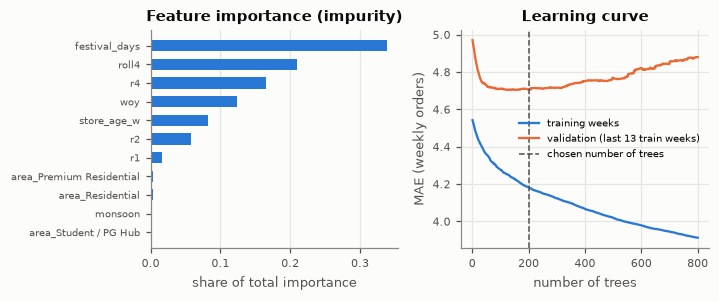

Validation MAE: best 4.70 at 133 trees; at 800 trees 4.88


In [6]:
best = gb.best_estimator_
imp = pd.Series(best.feature_importances_, index=REL).sort_values()
perm = permutation_importance(best, test[REL], np.log(y_test / test.roll4), n_repeats=10, random_state=SEED,
                              scoring="neg_mean_absolute_error")
perm_s = pd.Series(perm.importances_mean, index=REL).reindex(imp.index)
pd.DataFrame({"impurity importance": imp, "permutation importance": perm_s}).round(4).to_csv(f"{OUT}/feature_importance.csv")
# learning curve on a validation block: last 13 training weeks
val_start = train.week.max() - pd.Timedelta(weeks=12)
tr_in, val = train[train.week < val_start], train[train.week >= val_start]
curve_model = GradientBoostingRegressor(subsample=0.8, random_state=SEED, n_estimators=800,
                                        learning_rate=gb.best_params_["learning_rate"], max_depth=gb.best_params_["max_depth"])
curve_model.fit(tr_in[REL], np.log(tr_in.orders / tr_in.roll4))
tr_err = [mean_absolute_error(tr_in.orders, tr_in.roll4 * np.exp(p)) for p in curve_model.staged_predict(tr_in[REL])]
va_err = [mean_absolute_error(val.orders, val.roll4 * np.exp(p)) for p in curve_model.staged_predict(val[REL])]
fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.8))
axes[0].barh(imp.index, imp.values, color=BLUE, height=0.6)
axes[0].set(title="Feature importance (impurity)", xlabel="share of total importance"); axes[0].grid(axis="y", visible=False)
axes[0].tick_params(axis="y", labelsize=6.5)
axes[1].plot(range(1, 801), tr_err, color=BLUE, label="training weeks")
axes[1].plot(range(1, 801), va_err, color=ORANGE, label="validation (last 13 train weeks)")
axes[1].axvline(gb.best_params_["n_estimators"], color=INK2, ls="--", lw=1, label="chosen number of trees")
axes[1].set(title="Learning curve", xlabel="number of trees", ylabel="MAE (weekly orders)"); axes[1].legend(fontsize=6.5)
plt.tight_layout(); save_fig(fig, "importance_and_learning_curve")
print(f"Validation MAE: best {min(va_err):.2f} at {int(np.argmin(va_err)) + 1} trees; at 800 trees {va_err[-1]:.2f}")

## 6.3 Comparison with the PBL 1 models (same task, same test weeks, same metrics)

Noise floor: if weekly orders were Poisson around a perfect forecast, the MAE would still be ≈ 4.34


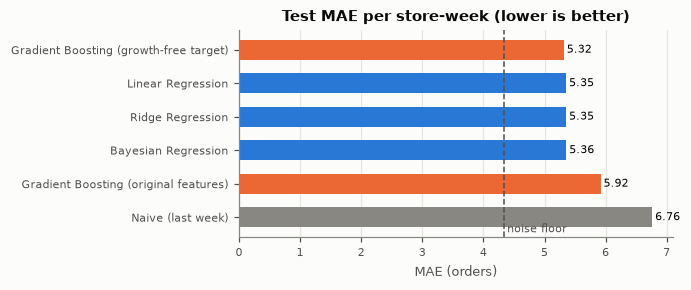

,MAE,RMSE,R²,WAPE
Naive (last week),6.761,8.918,0.644,0.207
Linear Regression,5.353,6.970,0.782,0.164
Ridge Regression,5.353,6.970,0.782,0.164
Bayesian Regression,5.356,6.975,0.782,0.164
Gradient Boosting (original features),5.917,8.050,0.710,0.181
Gradient Boosting (growth-free target),5.315,6.939,0.784,0.163


In [7]:
comp = pd.concat([pbl1, pd.DataFrame({"Gradient Boosting (original features)": metrics(y_test, p_raw),
                                      "Gradient Boosting (growth-free target)": metrics(y_test, p_gb)}).T])
comp.round(3).to_csv(f"{OUT}/comparison_with_pbl1.csv")
rng = np.random.default_rng(SEED)
lin_pred = pd.read_csv("results/05_regression/test_predictions.csv")["Linear Regression"].values
NOISE_FLOOR = float(np.mean([mean_absolute_error(rng.poisson(np.clip(lin_pred, 0.1, None)), lin_pred) for _ in range(200)]))
print(f"Noise floor: if weekly orders were Poisson around a perfect forecast, the MAE would still be ≈ {NOISE_FLOOR:.2f}")
fig, ax = plt.subplots(figsize=(6.3, 2.7))
order = comp.MAE.sort_values(ascending=False)
ax.barh(order.index, order.values, color=[ORANGE if "Boosting" in i else (MUTED if "Naive" in i else BLUE) for i in order.index], height=0.6)
for i, v in enumerate(order.values):
    ax.text(v + 0.05, i, f"{v:.2f}", va="center", fontsize=7.5)
ax.axvline(NOISE_FLOOR, color=INK2, ls="--", lw=1); ax.text(NOISE_FLOOR + 0.05, -0.45, "noise floor", fontsize=7, color=INK2)
ax.set(title="Test MAE per store-week (lower is better)", xlabel="MAE (orders)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); save_fig(fig, "comparison_mae")
comp.round(3)

In [8]:
pd.DataFrame({"store_id": test.store_id, "week": test.week, "actual": y_test,
              "gb_original": p_raw, "gb_growth_free": p_gb}).round(3).to_csv(f"{OUT}/test_predictions.csv", index=False)
joblib.dump({"model": best, "features": REL, "target": "log(orders / roll4)"}, f"{OUT}/gradient_boosting.joblib")
json.dump({"best_params": gb.best_params_, "search_time_s": round(GB_TIME, 1), "noise_floor_mae": round(NOISE_FLOOR, 3),
           **{f"{m}|{k}": round(float(v), 4) for m in comp.index for k, v in comp.loc[m].items()}},
          open(f"{OUT}/summary.json", "w"), indent=2)
for f in sorted(os.listdir(OUT)):
    print(f"{OUT}/{f}")

results/06_boosting/boosting_feature_analysis.png
results/06_boosting/comparison_mae.png
results/06_boosting/comparison_with_pbl1.csv
results/06_boosting/cv_results.csv
results/06_boosting/feature_importance.csv
results/06_boosting/gradient_boosting.joblib
results/06_boosting/importance_and_learning_curve.png
results/06_boosting/summary.json
results/06_boosting/test_predictions.csv


## 6.4 Interpretation
- Plain gradient boosting is **worse** than linear regression because trees cannot extrapolate the growth of the
  business into the test period.
- Modelling the growth-free ratio fixes this: the tuned model (200 trees, depth 2, learning rate 0.02) is the most
  accurate of all models — but only marginally (MAE 5.32 vs 5.35 for linear regression, about 0.7% better).
- Reason for the small gain: the remaining error is close to the noise floor (random week-to-week variation of the
  orders), and the signal in the lags is largely linear, so there is little non-linear structure left for the trees.
- Trade-off: gradient boosting needs a growth-free target, hyperparameter search (about 40 s) and is harder to explain;
  linear / Bayesian regression is almost as accurate, instant to train, and the Bayesian model also gives prediction
  intervals.